# Visualizing Chipotle's Data

### Step 1. Import the necessary libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# set this so the graphs open internally
%matplotlib inline

### Step 2. Import the chiptole.csv dataset

In [2]:
# df = pd.read_csv('../../00-data/chipotle.csv',index_col=0)

### Step 3. Assign it to a variable called chipo.

### Step 4. See the first 10 entries

### Step 5. Create a histogram of the top 5 items bought

In [3]:
# df.columns

In [4]:
# df['item_price'] = df['item_price'].str.replace('$','').str.strip().astype(float)

In [5]:
# df.to_csv('../week_02/cleaned_chipo.csv',index=False)

In [6]:
df2 = pd.read_csv('../../00-data/cleaned_chipo.csv')

<Axes: xlabel='item_name'>

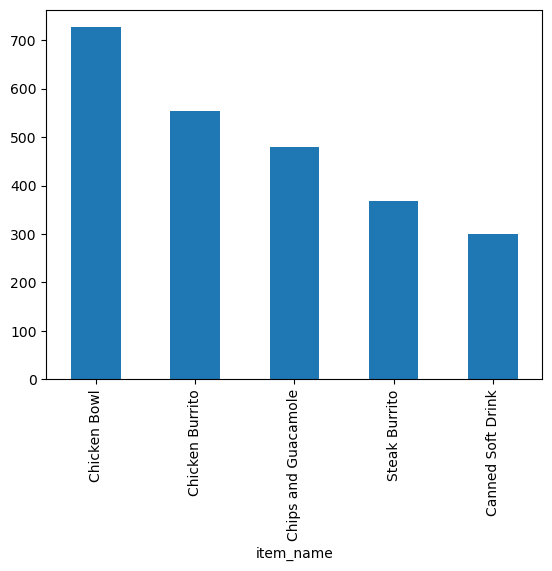

In [7]:
df2['item_name'].value_counts().head(5).plot(kind='bar')

### Step 6. Create a scatterplot with the number of items orderered per order price
#### Hint: Price should be in the X-axis and Items ordered in the Y-axis

In [8]:
df2.columns

Index(['order_id', 'quantity', 'item_name', 'choice_description',
       'item_price'],
      dtype='object')

In [9]:
orders = df2.groupby('order_id').agg(
    total_item = ('quantity','sum'),
    total_price =('item_price','sum')
)
orders

,total_item,total_price
order_id,,
1,4,11.56
2,2,16.98
3,2,12.67
4,2,21.00
5,2,13.70
...,...,...
1830,2,23.00
1831,3,12.90
1832,2,13.20


<Axes: xlabel='total_price', ylabel='total_item'>

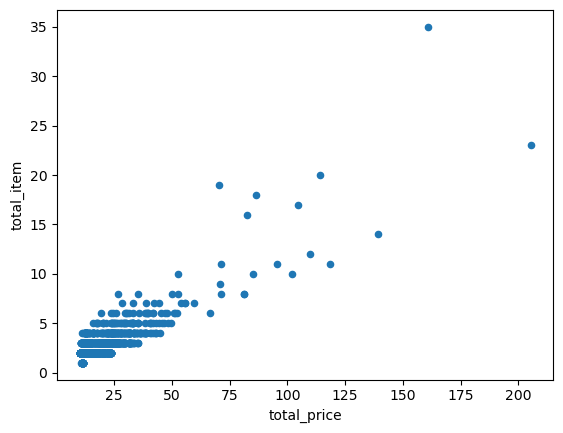

In [10]:
orders.plot(kind='scatter',x='total_price',y='total_item')

### Step 7. BONUS: Create a question and a graph to answer your own question.

In [11]:
# What is the average price per itme for 
# the top 10 most popular items ?

In [15]:
top10 = df2['item_name'].value_counts().head(10).index
top10
avg_price = (df2[df2['item_name'].isin(top10)]
             .groupby('item_name')['item_price']
             .mean().sort_values(ascending=False))

<Axes: ylabel='item_name'>

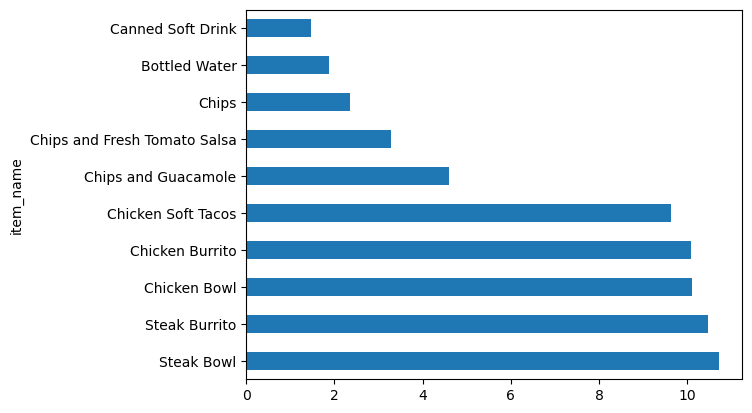

In [14]:
avg_price.plot(kind='barh')